# Лабораторная работа 12. Визуализация и первичный анализ данных

#Выполнил: Понкратов Владимир Александрович
#Группа: ИНБ-б-о-26-2

**Набор данных:** Breast Cancer Wisconsin (Diagnostic) — 569 пациенток, 30 признаков (встроен в scikit-learn).

**Соответствие учебному примеру:**

| Учебный пример (telecom_churn) | Мой набор |
|---|---|
| `Churn` (уход клиента) | `Malignant` (злокачественная опухоль) |
| `State` (категориальный) | `Size group` (4 группы по квантилям `worst area`) |
| признаки со словом `charge` | признаки со словом `mean` |
| `Total day charge` и `Total day minutes` | `mean radius`, `mean perimeter`, `mean area` |

### Подключение библиотек

In [1]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer

sns.set_theme(style="whitegrid")
%matplotlib inline

### Загрузка данных

In [2]:
!wget https://raw.githubusercontent.com/enikolaev/IT-and-Programming/refs/heads/main/data/pract12/telecom_churn.csv

--2026-11-15 12:16:05--  https://raw.githubusercontent.com/enikolaev/IT-and-Programming/refs/heads/main/data/pract12/telecom_churn.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 279997 (273K) [text/plain]
Saving to: ‘telecom_churn.csv’

telecom_churn.csv   100%[===================>] 273.43K  --.-KB/s    in 0.08s   

2026-11-15 12:16:06 (3.46 MB/s) - ‘telecom_churn.csv’ saved [279997/279997]



In [4]:
raw = load_breast_cancer(as_frame=True)
data = raw.frame.copy()

# target: 0 - злокачественная, 1 - доброкачественная
data["Malignant"] = data["target"] == 0
data = data.drop(columns="target")

# Категориальный признак (аналог State): группа по размеру опухоли
data["Size group"] = pd.qcut(data["worst area"], 4,
                             labels=["XS", "S", "M", "L"]).astype(str)

data.head(10)

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,Malignant,Size group
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,0.2419,0.07871,...,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,True,L
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,0.1812,0.05667,...,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,True,L
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,0.2069,0.05999,...,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,True,L
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,0.2597,0.09744,...,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,True,S
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,0.1809,0.05883,...,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,True,L
5,12.45,15.70,82.57,477.1,0.12780,0.17000,0.15780,0.08089,0.2087,0.07613,...,103.40,741.6,0.1791,0.5249,0.5355,0.1741,0.3985,0.12440,True,M
6,18.25,19.98,119.60,1040.0,0.09463,0.10900,0.11270,0.07400,0.1794,0.05742,...,153.20,1606.0,0.1442,0.2576,0.3784,0.1932,0.3063,0.08368,True,L
7,13.71,20.83,90.20,577.9,0.11890,0.16450,0.09366,0.05985,0.2196,0.07451,...,110.60,897.0,0.1654,0.3682,0.2678,0.1556,0.3196,0.11510,True,M
8,13.00,21.82,87.50,519.8,0.12730,0.19320,0.18590,0.09353,0.2350,0.07389,...,106.20,739.3,0.1703,0.5401,0.5390,0.2060,0.4378,0.10720,True,M
9,12.46,24.04,83.97,475.9,0.11860,0.23960,0.22730,0.08543,0.2030,0.08243,...,97.65,711.4,0.1853,1.0580,1.1050,0.2210,0.4366,0.20750,True,M


In [5]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 32 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         5

In [6]:
data.describe()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,16.269190,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,4.833242,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,7.930000,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,13.010000,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,14.970000,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,18.790000,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,36.040000,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500


### Одиночные признаки
#### Количественные признаки

In [7]:
data.columns

Index(['mean radius', 'mean texture', 'mean perimeter', 'mean area',
       'mean smoothness', 'mean compactness', 'mean concavity',
       'mean concave points', 'mean symmetry', 'mean fractal dimension',
       'radius error', 'texture error', 'perimeter error', 'area error',
       'smoothness error', 'compactness error', 'concavity error',
       'concave points error', 'symmetry error', 'fractal dimension error',
       'worst radius', 'worst texture', 'worst perimeter', 'worst area',
       'worst smoothness', 'worst compactness', 'worst concavity',
       'worst concave points', 'worst symmetry', 'worst fractal dimension',
       'Malignant', 'Size group'],
      dtype='object')

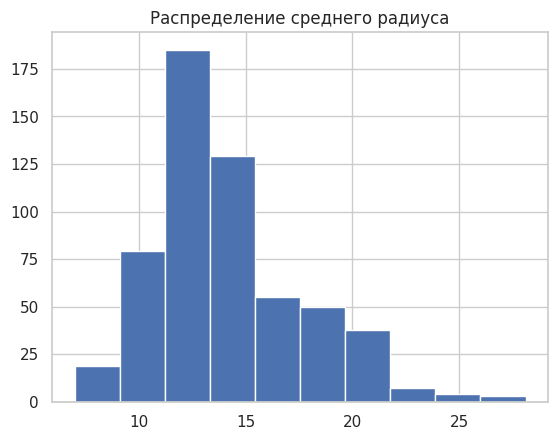

In [8]:
# Гистограмма средствами pandas (надстройка над matplotlib)
data["mean radius"].hist()
plt.title("Распределение среднего радиуса");

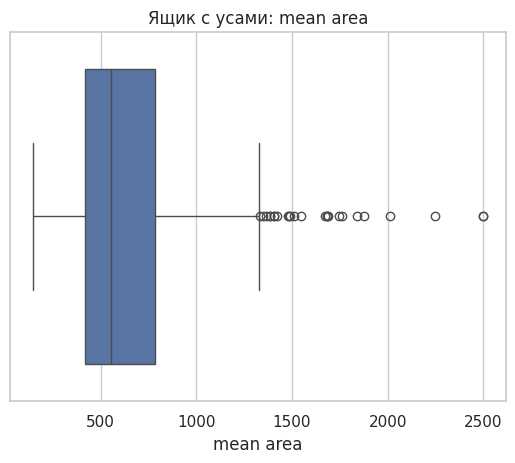

In [9]:
# Boxplot: медиана, квартили, межквартильный размах, выбросы
sns.boxplot(x=data["mean area"])
plt.title("Ящик с усами: mean area");

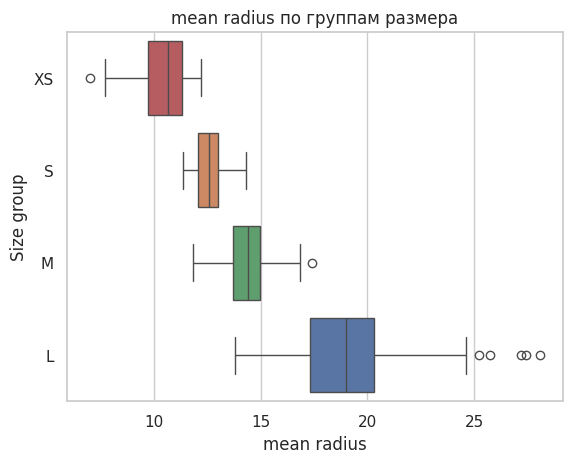

In [10]:
# Boxplot по категориям (аналог топ-3 штатов)
sns.boxplot(y="Size group", x="mean radius", data=data,
            hue="Size group", order=["XS", "S", "M", "L"])
plt.title("mean radius по группам размера");

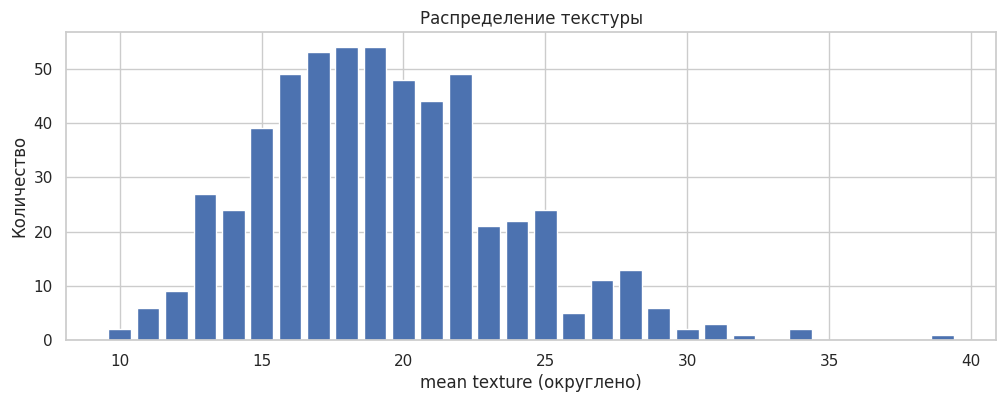

In [11]:
# Столбчатая диаграмма частот значений
hist = data["mean texture"].round(0).value_counts().sort_index()
plt.figure(figsize=(12, 4))
plt.bar(hist.index, hist)
plt.xlabel("mean texture (округлено)")
plt.ylabel("Количество")
plt.title("Распределение текстуры");

In [12]:
# Отбор признаков по подстроке в названии (аналог 'charge')
feats = [f for f in data.columns if "mean" in f and "fractal" not in f][:6]
feats

['mean radius',
 'mean texture',
 'mean perimeter',
 'mean area',
 'mean smoothness',
 'mean compactness']

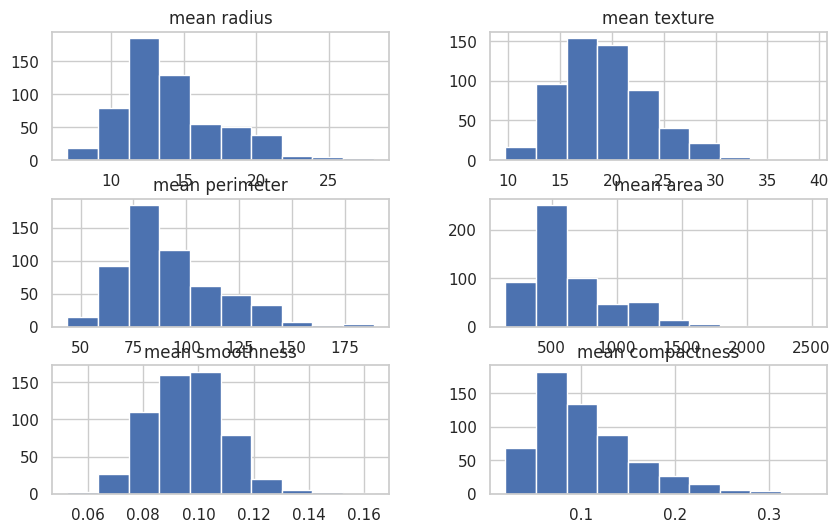

In [13]:
# Гистограммы нескольких признаков сразу
data[feats].hist(figsize=(10, 6));

### Категориальные признаки

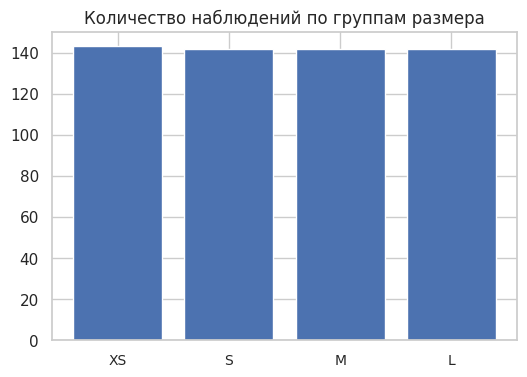

In [15]:
hist = data["Size group"].value_counts().reindex(["XS", "S", "M", "L"])
fig, ax = plt.subplots(1, 1, figsize=(6, 4))
ax.bar(hist.index, hist)
ax.tick_params(axis="x", labelsize=10)
ax.set_title("Количество наблюдений по группам размера")
plt.show()

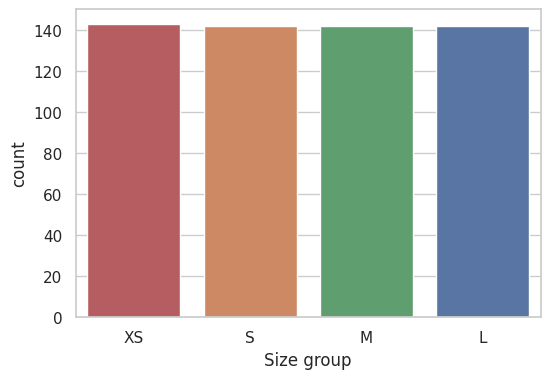

In [16]:
# countplot (seaborn)
fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(ax=ax, x="Size group", data=data, hue="Size group",
              order=["XS", "S", "M", "L"]);

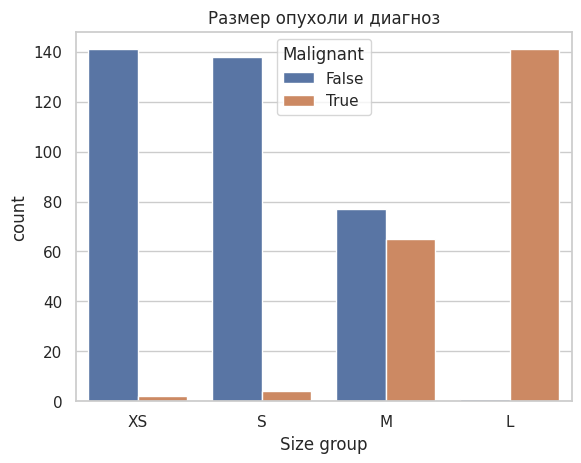

In [17]:
# countplot с разбивкой по целевому признаку
sns.countplot(x="Size group", hue="Malignant", data=data,
              order=["XS", "S", "M", "L"])
plt.title("Размер опухоли и диагноз");

### Взаимосвязанные признаки
#### Количественный - количественный

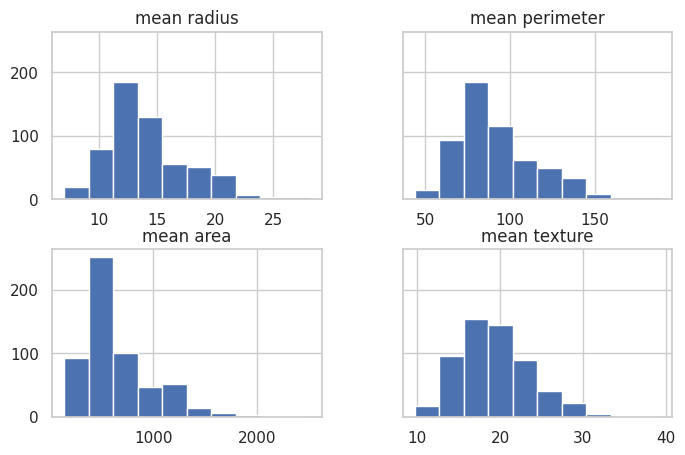

In [18]:
feats = ["mean radius", "mean perimeter", "mean area", "mean texture"]
data[feats].hist(figsize=(8, 5), sharey=True);

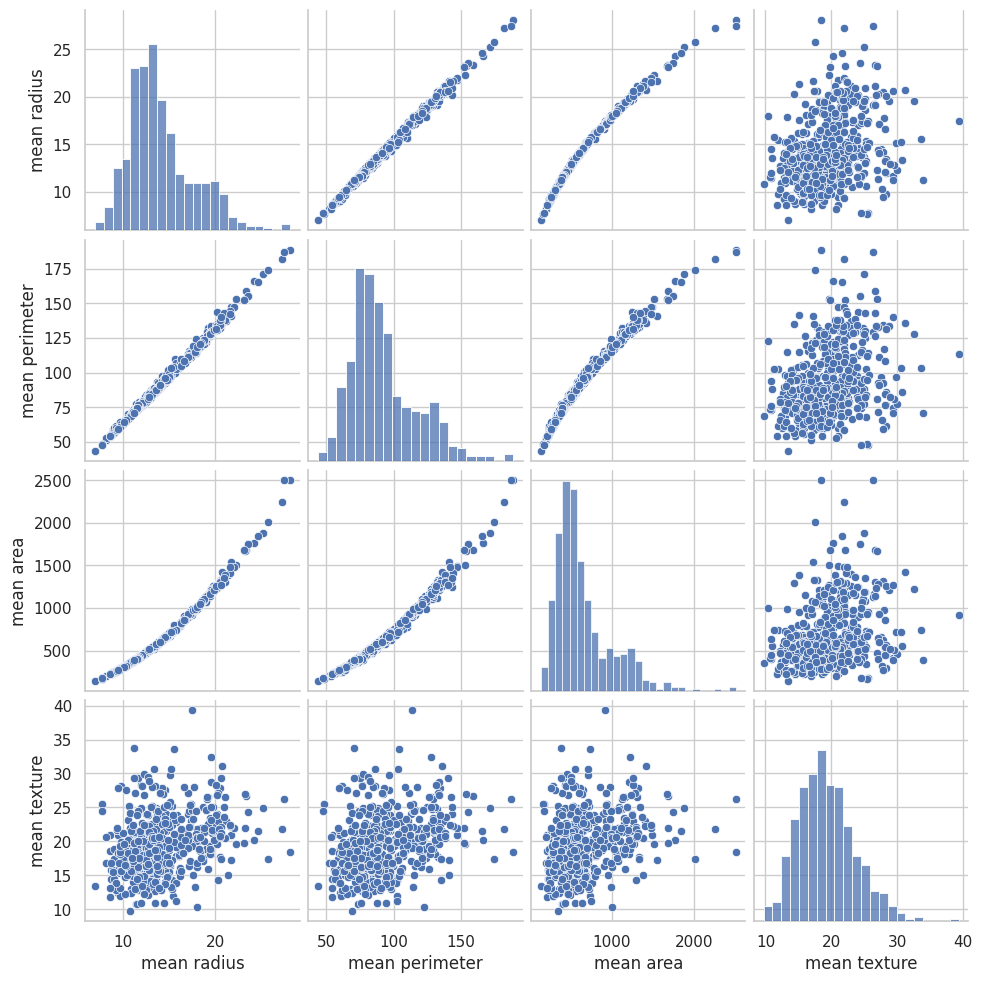

In [19]:
sns.pairplot(data[feats]);

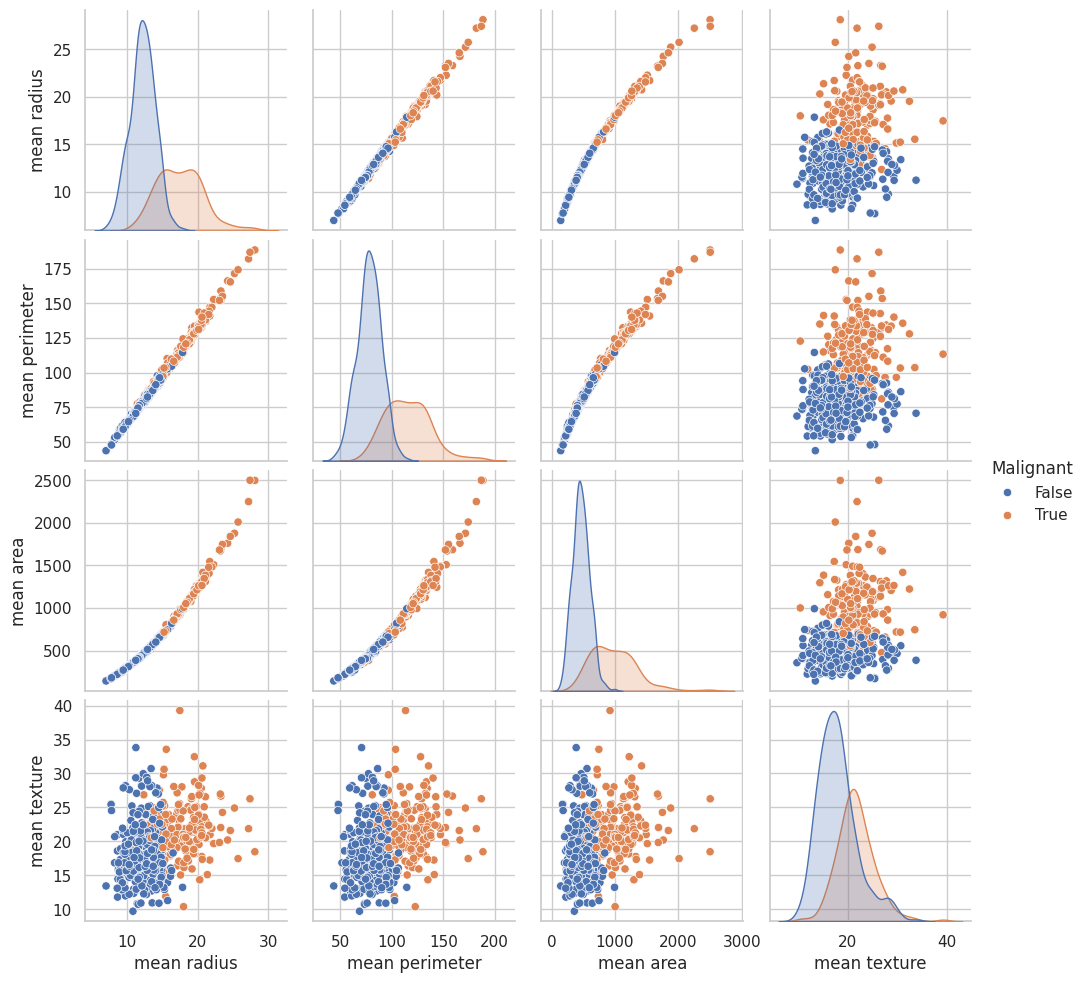

In [20]:
sns.pairplot(data[feats + ["Malignant"]], hue="Malignant");

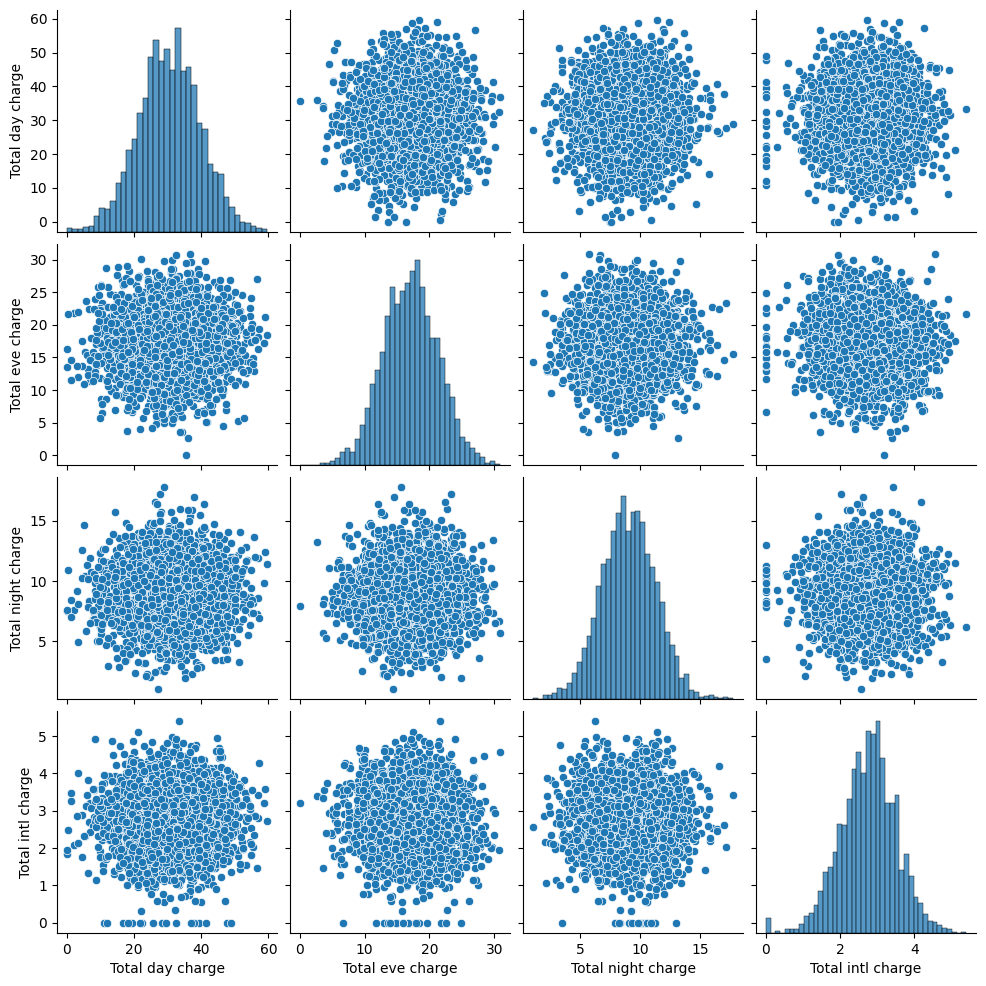

In [ ]:
# Попарное распределение признаков
# Применение Seaborn
sns.pairplot(data[feats]);

Можно строить более сложные попарные распределения признаков

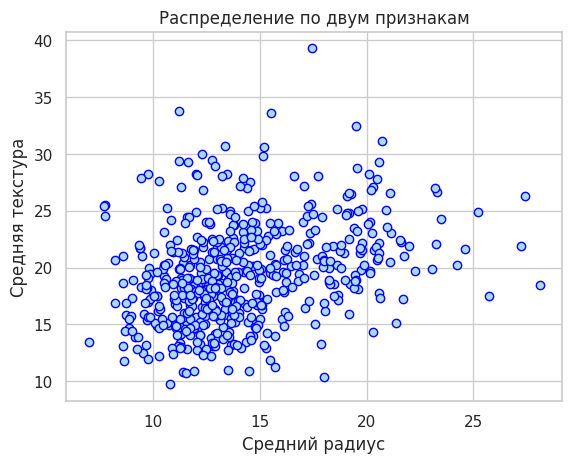

In [21]:
# Диаграмма рассеяния с подписями и заголовком
plt.scatter(data["mean radius"], data["mean texture"],
            color="lightblue", edgecolors="blue")
plt.xlabel("Средний радиус")
plt.ylabel("Средняя текстура")
plt.title("Распределение по двум признакам");

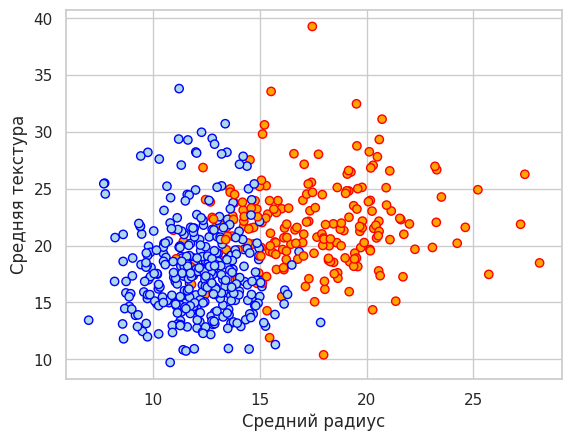

In [22]:
# Раскраска по целевому признаку через map
c = data["Malignant"].map({False: "lightblue", True: "orange"})
edge_c = data["Malignant"].map({False: "blue", True: "red"})
plt.scatter(data["mean radius"], data["mean texture"],
            color=c, edgecolors=edge_c)
plt.xlabel("Средний радиус")
plt.ylabel("Средняя текстура");

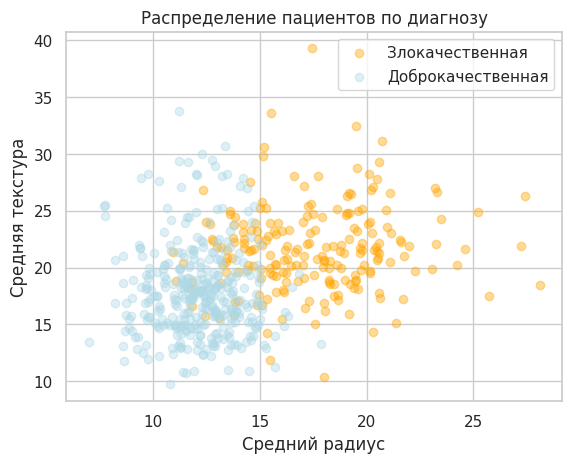

In [23]:
# Раскраска с легендой
data_mal = data[data["Malignant"]]
data_ben = data[~data["Malignant"]]

plt.scatter(data_mal["mean radius"], data_mal["mean texture"],
            color="orange", alpha=0.4, label="Злокачественная")
plt.scatter(data_ben["mean radius"], data_ben["mean texture"],
            color="lightblue", alpha=0.4, label="Доброкачественная")
plt.xlabel("Средний радиус")
plt.ylabel("Средняя текстура")
plt.title("Распределение пациентов по диагнозу")
plt.legend();

### Корреляция признаков

In [24]:
num_feats = [
    "mean radius", "mean texture", "mean perimeter", "mean area",
    "mean smoothness", "mean compactness", "mean concavity",
    "mean concave points", "mean symmetry", "mean fractal dimension",
    "radius error", "texture error", "area error",
    "worst radius", "worst texture", "worst perimeter", "worst area",
    "Malignant",
]
cdata = data[num_feats]
cdata.corr()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,area error,worst radius,worst texture,worst perimeter,worst area,Malignant
mean radius,1.000000,0.323782,0.997855,0.987357,0.170581,0.506124,0.676764,0.822529,0.147741,-0.311631,0.679090,-0.097317,0.735864,0.969539,0.297008,0.965137,0.941082,0.730029
mean texture,0.323782,1.000000,0.329533,0.321086,-0.023389,0.236702,0.302418,0.293464,0.071401,-0.076437,0.275869,0.386358,0.259845,0.352573,0.912045,0.358040,0.343546,0.415185
mean perimeter,0.997855,0.329533,1.000000,0.986507,0.207278,0.556936,0.716136,0.850977,0.183027,-0.261477,0.691765,-0.086761,0.744983,0.969476,0.303038,0.970387,0.941550,0.742636
mean area,0.987357,0.321086,0.986507,1.000000,0.177028,0.498502,0.685983,0.823269,0.151293,-0.283110,0.732562,-0.066280,0.800086,0.962746,0.287489,0.959120,0.959213,0.708984
mean smoothness,0.170581,-0.023389,0.207278,0.177028,1.000000,0.659123,0.521984,0.553695,0.557775,0.584792,0.301467,0.068406,0.246552,0.213120,0.036072,0.238853,0.206718,0.358560
mean compactness,0.506124,0.236702,0.556936,0.498502,0.659123,1.000000,0.883121,0.831135,0.602641,0.565369,0.497473,0.046205,0.455653,0.535315,0.248133,0.590210,0.509604,0.596534
mean concavity,0.676764,0.302418,0.716136,0.685983,0.521984,0.883121,1.000000,0.921391,0.500667,0.336783,0.631925,0.076218,0.617427,0.688236,0.299879,0.729565,0.675987,0.696360
mean concave points,0.822529,0.293464,0.850977,0.823269,0.553695,0.831135,0.921391,1.000000,0.462497,0.166917,0.698050,0.021480,0.690299,0.830318,0.292752,0.855923,0.809630,0.776614
mean symmetry,0.147741,0.071401,0.183027,0.151293,0.557775,0.602641,0.500667,0.462497,1.000000,0.479921,0.303379,0.128053,0.223970,0.185728,0.090651,0.219169,0.177193,0.330499
mean fractal dimension,-0.311631,-0.076437,-0.261477,-0.283110,0.584792,0.565369,0.336783,0.166917,0.479921,1.000000,0.000111,0.164174,-0.090170,-0.253691,-0.051269,-0.205151,-0.231854,-0.012838


В реальных задачах анализ такой матрицы затруднен,
необходимо или автоматизировать (скрипты), или визуализировать (графики)

Text(0.5, 1.0, 'Матрица корреляций')

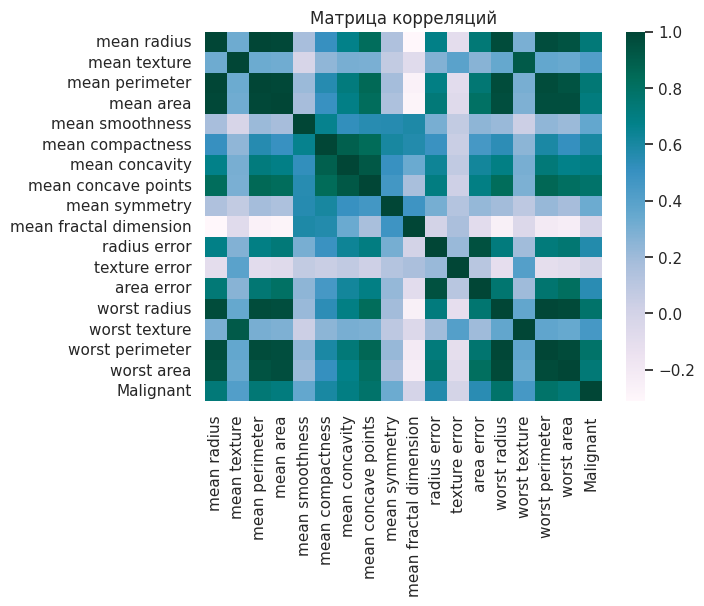

In [25]:
sns.heatmap(cdata.corr(), cmap=plt.cm.PuBuGn)
plt.title("Матрица корреляций")

Из карты heatmap видно, что некоторые признаки коррелируют:
например сильная корреляция в парах (total day charge, total day minutes),
(total night charge, total night minutes).
Из таких пар можно удалить один признак

Радиус, периметр и площадь почти линейно зависят друг от друга (корреляция около 1). Из таких групп достаточно оставить один признак.

In [26]:
# Автоматический поиск самых коррелирующих пар
corr = cdata.corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
pairs = upper.stack().sort_values(ascending=False)
pairs.head(5)

,,0
mean radius,mean perimeter,0.997855
worst radius,worst perimeter,0.993708
mean radius,mean area,0.987357
mean perimeter,mean area,0.986507
worst radius,worst area,0.984015


Перестраиваем heatmap без коррелирующих признаков

In [27]:
# Удаление коррелирующих признаков
del_feats = ["mean perimeter", "mean area", "worst radius",
             "worst perimeter", "worst area"]
data_uncorr = cdata.drop(del_feats, axis=1)
data_uncorr.columns

Index(['mean radius', 'mean texture', 'mean smoothness', 'mean compactness',
       'mean concavity', 'mean concave points', 'mean symmetry',
       'mean fractal dimension', 'radius error', 'texture error', 'area error',
       'worst texture', 'Malignant'],
      dtype='object')

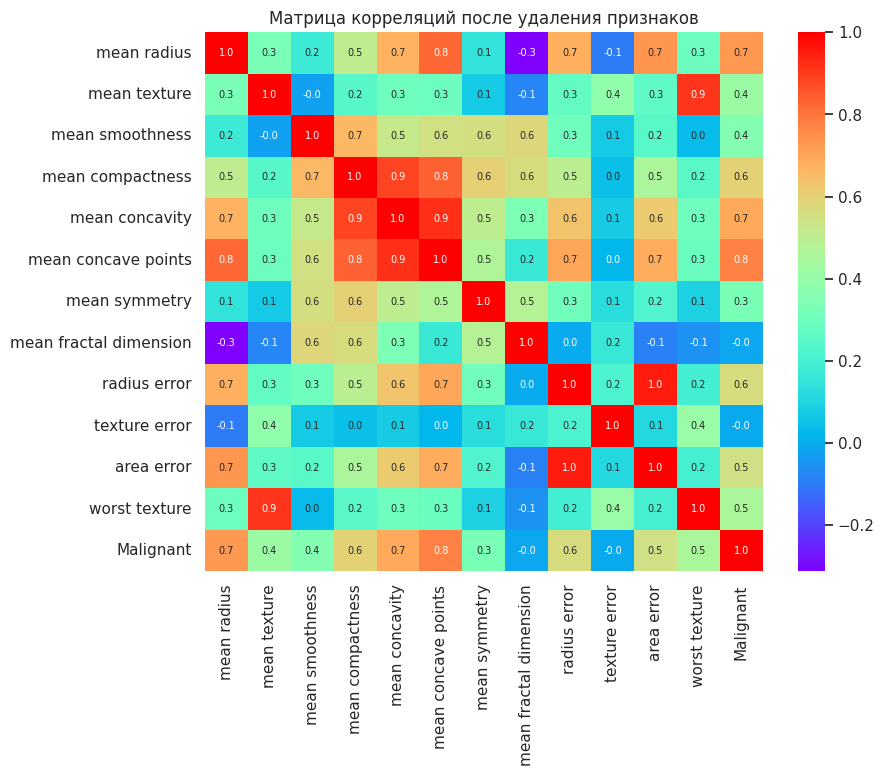

In [28]:
# Heatmap без коррелирующих признаков
plt.figure(figsize=(9, 7))
sns.heatmap(data_uncorr.corr(), cmap=plt.cm.rainbow, annot=True, fmt=".1f",
            annot_kws={"size": 7})
plt.title("Матрица корреляций после удаления признаков");

#Ответы на контрольные вопросы:
1. Какие библиотеки Python используются для построения графиков?
matplotlib (базовая библиотека), seaborn (надстройка над matplotlib для статистических графиков), pandas (методы .plot() и .hist() внутри DataFrame), а также plotly, bokeh, altair (интерактивные графики).

2. Основные типы графиков и функции
| Тип графика | Функции | Что показывает и когда применять |
|---|---|---|
| Линейный | `plt.plot()`, `sns.lineplot()` | Изменение величины по порядку, чаще всего во времени (динамика, тренды, временные ряды). |
| Диаграмма рассеяния | `plt.scatter()`, `sns.scatterplot()` | Каждое наблюдение отображается точкой (x, y). Нужна для поиска связи между двумя количественными признаками. Цвет и размер точек могут кодировать третий признак. |
| Столбчатая диаграмма | `plt.bar()`, `plt.barh()`, `sns.barplot()`, `sns.countplot()` | Сравнение значений по категориям. countplot сам считает количество наблюдений в каждой категории. |
| Гистограмма | `plt.hist()`, `df.hist()`, `sns.histplot()` | Распределение одного количественного признака: значения делятся на интервалы (bins), для каждого показано число наблюдений. |
| Круговая диаграмма | `plt.pie()` | Доли частей в целом. Подходит при небольшом числе категорий (до 5–6). |
| «Ящик с усами» | `sns.boxplot()`, `plt.boxplot()` | Медиана, квартили, межквартильный размах и выбросы. Удобно сравнивать распределения по группам. |
| Скрипичная диаграмма | `sns.violinplot()` | Объединяет boxplot и оценку плотности распределения, показывая форму распределения. |
| Тепловая карта | `sns.heatmap()`, `plt.imshow()` | Значения матрицы отображаются цветом. Чаще всего применяется для матрицы корреляций df.corr(). |
| Попарные графики | `sns.pairplot()` | Матрица диаграмм рассеяния для всех пар признаков, на диагонали гистограммы. Даёт быстрый обзор связей в данных. |

3. scatter()
Строит диаграмму рассеяния: каждое наблюдение отображается точкой с координатами (x, y). Используется для поиска связи между двумя количественными признаками. Параметры color, s (размер), alpha (прозрачность), edgecolors, label позволяют кодировать дополнительные признаки цветом и размером.

4. corr()
Метод DataFrame, который вычисляет матрицу попарных коэффициентов корреляции между числовыми столбцами (по умолчанию Пирсона; также spearman, kendall). Значения лежат от −1 до 1: близко к ±1 означает сильную линейную связь, около 0 означает её отсутствие.

5. hist()
Строит гистограмму: разбивает диапазон значений на интервалы (bins) и показывает, сколько наблюдений попало в каждый. Позволяет оценить форму распределения признака, выбросы и асимметрию. У DataFrame df.hist() рисует гистограммы сразу для нескольких столбцов.

6. Назначение pandas
Библиотека для обработки и анализа табличных данных: чтение и запись (CSV, Excel, SQL, JSON), фильтрация, группировка (groupby), объединение таблиц, работа с пропусками, агрегация, временные ряды, а также быстрая визуализация.

7. head() и tail()
head(n) выводит первые n строк таблицы, tail(n) выводит последние n строк. По умолчанию n = 5. Используются для быстрой проверки того, что данные загрузились правильно.

8. DataFrame
Двумерная таблица с именованными столбцами (каждый имеет свой тип данных) и индексом строк. Это основная структура pandas для хранения и обработки данных. Можно считать её аналогом листа Excel или таблицы SQL.

9. info() и describe()

info() выводит структуру таблицы: число строк, названия столбцов, типы данных, количество непустых значений и объём памяти. Помогает найти пропуски и неверные типы.
describe() выводит описательную статистику числовых столбцов: count, mean, std, min, 25%, 50% (медиана), 75%, max. Для категориальных столбцов (include='object') выводит count, unique, top, freq.

10. heatmap()
Функция seaborn для построения тепловой карты: значения матрицы отображаются цветом. Чаще всего используется для матрицы корреляций df.corr(). Параметры: cmap (палитра), annot=True (числа в ячейках), fmt (формат чисел), vmin/vmax (границы цветовой шкалы), center.

11. Установка размера графика

plt.figure(figsize=(ширина, высота)) перед построением (размер в дюймах).
fig, ax = plt.subplots(figsize=(15, 5)).
plt.rcParams['figure.figsize'] = (10, 6) задаёт размер для всех графиков.
Параметр figsize в df.hist(), df.plot().
fig.set_size_inches(w, h) для уже созданного рисунка.
В seaborn: plt.figure(figsize=...) перед вызовом; для функций, создающих собственный рисунок (pairplot, catplot), используются параметры height и aspect.

12. Шрифт, подписи осей и легенда

Шрифт осей: plt.xticks(fontsize=8, font='monospace'), plt.yticks(...), ax.tick_params(axis='x', labelsize=8), а для общего шрифта plt.rcParams['font.size'] = 12 или plt.rcParams['font.family'] = ....
Подписи осей: plt.xlabel('текст'), plt.ylabel('текст'), для объекта ax это ax.set_xlabel(), ax.set_ylabel(). Заголовок графика задаётся через plt.title() или ax.set_title().
Текст легенды: параметр label='...' при построении каждой серии, затем plt.legend(). Можно задать вручную: plt.legend(['Ушли', 'Остались'], title='Клиенты', loc='upper right').